# Реализация Логистической Регрессии

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [ ]:
class CustomLogisticRegression:
    def __init__(self, lr=0.1, epochs=1000, batch_size=None, alpha=0.0, random_state=42):
        self.lr = lr                  
        self.epochs = epochs          
        self.batch_size = batch_size  
        self.alpha = alpha            
        self.random_state = random_state
        
        self.weights_ = None         
        self.intercept_ = None       
        self.loss_history_ = []      

    @staticmethod
    def _sigmoid(z):

        z_clipped = np.clip(z, -500.0, 500.0)
        return 1.0 / (1.0 + np.exp(-z_clipped))

    def _compute_log_loss(self, y_true, y_prob, theta_weights):
        
        m = len(y_true)
        eps = 1e-15
        p_clipped = np.clip(y_prob, eps, 1.0 - eps)
        bce = -np.mean(y_true * np.log(p_clipped) + (1.0 - y_true) * np.log(1.0 - p_clipped))
        l2_penalty = (self.alpha / (2.0 * m)) * np.sum(theta_weights ** 2)
        return float(bce + l2_penalty)

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
            
        m, d = X.shape
        X_b = np.hstack([np.ones((m, 1)), X])
        
        rng = np.random.default_rng(self.random_state)
        theta = np.zeros(d + 1)
        self.loss_history_ = []
        batch_size = m if self.batch_size is None else min(self.batch_size, m)

        for epoch in range(self.epochs):
            indices = rng.permutation(m)
            X_shuf, y_shuf = X_b[indices], y[indices]

            for start in range(0, m, batch_size):
                X_batch = X_shuf[start:start + batch_size]
                y_batch = y_shuf[start:start + batch_size]
                b_len = len(y_batch)

                logits = X_batch @ theta
                probs = self._sigmoid(logits)

                errors = probs - y_batch
                reg_grad = self.alpha * np.r_[0.0, theta[1:]]
                grad = (1.0 / b_len) * (X_batch.T @ errors + reg_grad)

    
                theta -= self.lr * grad

            full_probs = self._sigmoid(X_b @ theta)
            self.loss_history_.append(self._compute_log_loss(y, full_probs, theta[1:]))

        self.intercept_ = float(theta[0])
        self.weights_ = theta[1:]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        prob_pos = self._sigmoid(X @ self.weights_ + self.intercept_)
        return np.column_stack([1.0 - prob_pos, prob_pos])

    def predict(self, X, threshold=0.5):
        probs_pos = self.predict_proba(X)[:, 1]
        return (probs_pos >= threshold).astype(int)

    def score(self, X, y):
        y_true = np.asarray(y, dtype=int).ravel()
        y_pred = self.predict(X)
        return float(np.mean(y_true == y_pred))

## Тестирование и сравнение 

[Custom Logistic]  w0 = -0.5885, w = [1.1934 4.2369] | Test Accuracy = 0.9100
[Sklearn Logistic] w0 = -0.8805, w = [1.5193 4.9579] | Test Accuracy = 0.9100


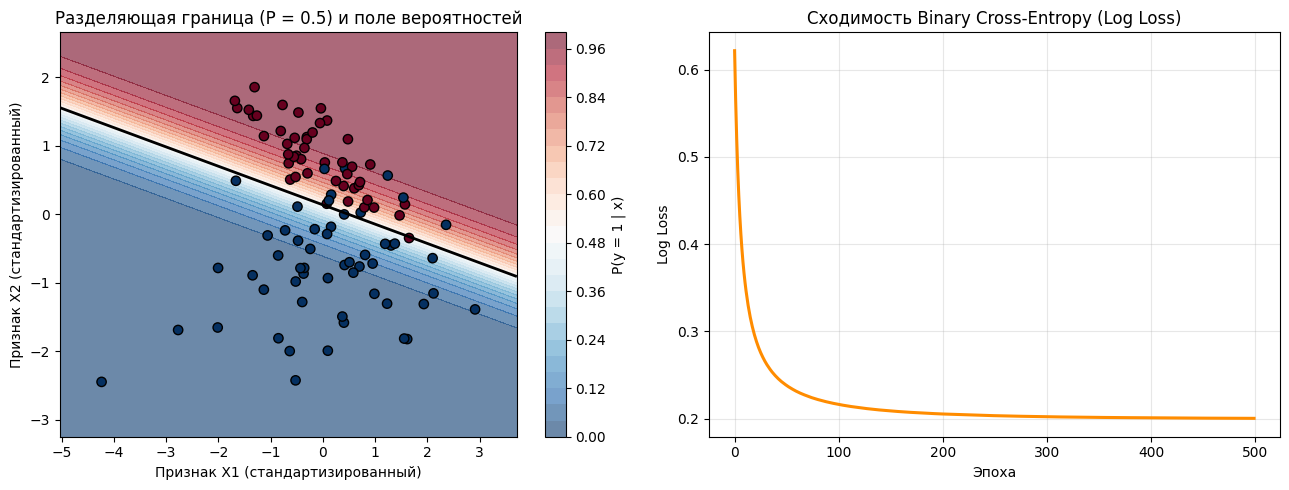

In [3]:
# Генерируем двумерный датасет для наглядной отрисовки разделяющей гиперплоскости
X, y = make_classification(
    n_samples=400, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, class_sep=1.2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Обучаем наш класс логистической регрессии
custom_clf = CustomLogisticRegression(lr=0.1, epochs=500, batch_size=64, alpha=0.1).fit(X_train_scaled, y_train)

# 2. Обучаем эталон из scikit-learn
sk_clf = LogisticRegression(C=10.0).fit(X_train_scaled, y_train)

print(f"[Custom Logistic]  w0 = {custom_clf.intercept_:.4f}, w = {np.round(custom_clf.weights_, 4)} | Test Accuracy = {custom_clf.score(X_test_scaled, y_test):.4f}")
print(f"[Sklearn Logistic] w0 = {sk_clf.intercept_[0]:.4f}, w = {np.round(sk_clf.coef_[0], 4)} | Test Accuracy = {sk_clf.score(X_test_scaled, y_test):.4f}")

# Визуализация разделяющей границы и кривой обучения Log Loss
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x_min, x_max = X_test_scaled[:, 0].min() - 0.8, X_test_scaled[:, 0].max() + 0.8
y_min, y_max = X_test_scaled[:, 1].min() - 0.8, X_test_scaled[:, 1].max() + 0.8
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_probs = custom_clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

contour = axes[0].contourf(xx, yy, grid_probs, levels=25, cmap="RdBu_r", alpha=0.6)
axes[0].contour(xx, yy, grid_probs, levels=[0.5], colors="black", linewidths=2)
axes[0].scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_test, cmap="RdBu_r", edgecolors="k", s=45)
axes[0].set_title("Разделяющая граница (P = 0.5) и поле вероятностей")
axes[0].set_xlabel("Признак X1 (стандартизированный)")
axes[0].set_ylabel("Признак X2 (стандартизированный)")
fig.colorbar(contour, ax=axes[0], label="P(y = 1 | x)")

axes[1].plot(custom_clf.loss_history_, color="darkorange", linewidth=2.2)
axes[1].set_title("Сходимость Binary Cross-Entropy (Log Loss)")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Log Loss")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()